# Numerical simulation for double-bracket quantum algorithms for quantum imaginary-time evolution (DB-QITE) using density matrix exponentiation (DME)

## 1. Initialization

In [158]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.linalg import expm

import sys
sys.path.append('..')
from functions.qite_gci import *
from functions.qite_dme import *
from functions.plot_bloch_sphere import *

plt.rcParams['axes.labelsize'] = 16
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['font.size'] = 16
plt.rcParams['savefig.dpi'] = 75
plt.rcParams['lines.linewidth'] = 2.0
plt.rcParams['lines.markersize'] = 8
plt.rcParams['legend.fontsize'] = 14
plt.rcParams['legend.labelspacing'] = .3
plt.rcParams['legend.columnspacing']= .3
plt.rcParams['legend.handletextpad']= .1
plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = "serif"
plt.rcParams['font.serif'] = "cm"
plt.rcParams["figure.figsize"] = [5, 3.50]
plt.rcParams["figure.autolayout"] = True

import warnings
warnings.filterwarnings("ignore", category=UserWarning)


## 2. Run DB-QITE with DME

### 2.1 Find optimal s

In [159]:
optimal_s_Mk = np.load('optimal_s_Mk.npy')

In [160]:
optimal_s_Mk[0][:1]

array([0.78539816])

### 2.2 k=1

In [161]:
Ms = [1, 2, 50]
k = 1

# Initial state sweep
thetas = np.linspace(0, 1, 100)
sigma_x = np.array([[0, 1], [1, 0]])
psis = [expm(-1j * np.pi/2 * sigma_x * t) @ np.array([[0], [1]]) for t in thetas]
psis = np.asarray(psis)

# Baseline GCI energy results
res_init = [GCI(initial_psi, psi, 1, np.linspace(0.01, 1, 2)).execute_gci()[0][-1] for psi in psis]

# Run DB-QITE for each M with optimal s
dict_res_DBQITE = {}
for M in Ms:
    res_DBQITE = [GCI(QITE_dme_select_M(M), psi, None, optimal_s_Mk[M-1][:k]).execute_gci()[0][-1] for psi in psis]
    dict_res_DBQITE[f'M={np.round(M,2)}'] = res_DBQITE

    print(f"M = {M}, k = {k}: s = {np.round(optimal_s_Mk[M-1][:k], 2)}, φ = {np.round(np.sqrt(optimal_s_Mk[M-1][:k]), 2)}")
    print(f"t = {np.round(np.sqrt(optimal_s_Mk[M-1][:k]) / (2 * np.pi * M), 4)} τ")

# Compute fidelities: (1 - E)/2
dict_fid_RGCI = {key: [(1 - E) / 2 for E in values] for key, values in dict_res_DBQITE.items()}

0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of inter

In [ ]:
import numpy as np

# Define your function that converts a state vector to density matrix
def state_to_density_matrix(state_vector):
    return np.outer(state_vector, state_vector.conj())

# Define the Pauli basis for a single qubit (column vectors)
pauli_bases = [
    np.array([[1], [0]]),  # |0>
    np.array([[0], [1]]),  # |1>
    np.array([[1/np.sqrt(2)], [1/np.sqrt(2)]]),  # |+>
    np.array([[1/np.sqrt(2)], [-1/np.sqrt(2)]])  # |->
]

# Define your operation (replace with your actual quantum operation function)
def quantum_operation(state):
    # This is a placeholder, replace with your actual operation
    return state_to_density_matrix(state)

# Function to perform process tomography
def process_tomography_1q(quantum_operation):
    # Prepare the Choi matrix (initialized to zeros)
    choi_matrix = np.zeros((4, 4), dtype=complex)
    
    # Loop over the Pauli bases
    for i, input_state in enumerate(pauli_bases):
        # Get the output density matrix for the input state
        output_state = quantum_operation(input_state)
        
        # Construct the matrix elements for the Choi matrix
        for j, output_basis in enumerate(pauli_bases):
            choi_matrix[i, j] = np.trace(np.dot(output_state, state_to_density_matrix(output_basis)))
    
    # Now, you can process the choi_matrix further, e.g., extract the process matrix
    return choi_matrix

In [ ]:
# Define the Pauli basis for a 2-qubit system
pauli_bases_2q = [
    np.array([[1], [0], [0], [0]]),  # |00>
    np.array([[0], [1], [0], [0]]),  # |01>
    np.array([[0], [0], [1], [0]]),  # |10>
    np.array([[0], [0], [0], [1]]),  # |11>
]

# Function to perform process tomography for a 2-qubit system
def process_tomography_2q(quantum_operation):
    # Prepare the Choi matrix (initialized to zeros)
    choi_matrix = np.zeros((16, 16), dtype=complex)  # 4x4 system, so Choi matrix is 16x16
    
    # Loop over the Pauli bases for the input states
    for i, input_state in enumerate(pauli_bases_2q):
        # Get the output density matrix for the input state
        output_state = quantum_operation(input_state)
        
        # Construct the matrix elements for the Choi matrix
        for j, output_basis in enumerate(pauli_bases_2q):
            choi_matrix[i * 4 + j, :] = np.reshape(output_state @ np.reshape(output_basis, -1), -1)  # flatten for Choi
    
    # Now, you can process the choi_matrix further, e.g., extract the process matrix
    return choi_matrix


In [214]:
def test(psi):
    return np.array([[0.+0.00000000e+00j, 0.+0.00000000e+00j],
       [0.+0.00000000e+00j, 1.+9.67743679e-18j]])

process_tomography(test)

array([[0. +0.00000000e+00j, 1. +9.67743679e-18j, 0.5+4.83871839e-18j,
        0.5+4.83871839e-18j],
       [0. +0.00000000e+00j, 1. +9.67743679e-18j, 0.5+4.83871839e-18j,
        0.5+4.83871839e-18j],
       [0. +0.00000000e+00j, 1. +9.67743679e-18j, 0.5+4.83871839e-18j,
        0.5+4.83871839e-18j],
       [0. +0.00000000e+00j, 1. +9.67743679e-18j, 0.5+4.83871839e-18j,
        0.5+4.83871839e-18j]])

In [215]:
def dbqite_M1_k1(psi):
    return GCI(QITE_dme_select_M(1), psi, None, optimal_s_Mk[0][:1]).execute_gci()[-2]
process_tomography(dbqite_M1_k1)

array([[1.  -9.67743679e-18j, 0.  +0.00000000e+00j, 0.5 -4.83871839e-18j,
        0.5 -4.83871839e-18j],
       [0.  +0.00000000e+00j, 1.  +9.67743679e-18j, 0.5 +4.83871839e-18j,
        0.5 +4.83871839e-18j],
       [0.75+3.29070150e-18j, 0.25-3.29070150e-18j, 0.75+0.00000000e+00j,
        0.25+0.00000000e+00j],
       [0.75+3.29070150e-18j, 0.25-3.29070150e-18j, 0.25+0.00000000e+00j,
        0.75+0.00000000e+00j]])

c:\Python\Lib\site-packages\matplotlib\cbook.py:1709: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Python\Lib\site-packages\matplotlib\cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


(1, 0.68)
(2, 0.62)
(50, 0.52)


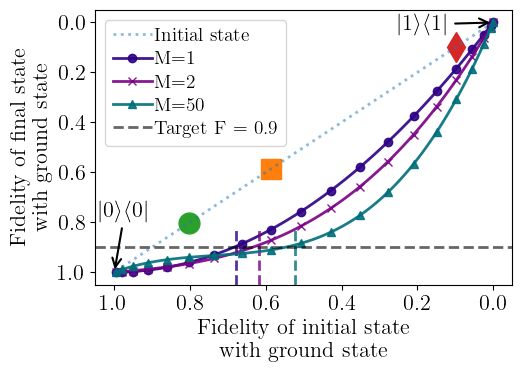

In [162]:
target_fidelity = 0.9

# Define reference state |0⟩⟨0|
state_0 = np.array([1, 0], dtype=complex)

# Fidelity with respect to |0⟩ for both pure and mixed states
def fidelity_with_0(state):
    return np.real(np.conj(state_0).T @ (state @ state.T.conj() if state.ndim == 2 and state.shape[1] == 1 else state) @ state_0)

# Initial state fidelities and RGCI outputs
fidelities_original = [fidelity_with_0(x) for x in psis]
fidelity = [(1 - E) / 2 for E in res_init]

# Plot setup
color = ['#2c0084', '#7a0085', '#006f7a', 'C0']
markers = ['o','x','^','*','P','*','h']
max_ext_list = []
 
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(fidelities_original, fidelity, label="Initial state", alpha=0.5, linestyle=':')

# Highlight three specific points
plt.plot(fidelities_original[70], fidelity[70], 'o', color='C2', markersize=15, zorder=0)
plt.plot(fidelities_original[55], fidelity[55], 's', color='C1', markersize=15, zorder=0)
plt.plot(fidelities_original[20], fidelity[20], 'd', color='C3', markersize=15, zorder=0)

# Plot each RGCI curve and draw vertical line at max excitation fidelity above target
for i, (key, value) in enumerate(dict_fid_RGCI.items()):
    max_ext = max_excitation(fidelities_original, np.real(value), target_fidelity)
    if max_ext: ax.axvline(x=max_ext, ymax=0.2, color=color[i], alpha=0.8, linestyle='--')
    max_ext_list.append(max_ext)
    ax.plot(fidelities_original, value, label=key, color=color[i],
            marker=markers[i], markevery=5, markersize=6, alpha=0.9)

# Reverse axes: higher overlap → left/lower corner
plt.gca().invert_xaxis()
plt.gca().invert_yaxis()
ax.axhline(y=target_fidelity, color='k', alpha=0.6, linestyle='--', label=f'Target F = {target_fidelity}')

# Labels and legend
ax.set_xlabel('Fidelity of initial state\nwith ground state')
ax.set_ylabel('Fidelity of final state\nwith ground state')
ax.legend()

# Annotate |1⟩ and |0⟩ 
ax.annotate(r'$|1\rangle\langle 1|$', xy=(fidelities_original[0], fidelity[0]), 
            xytext=(fidelities_original[0]+0.25, fidelity[0]+0.03), arrowprops=dict(arrowstyle='->', lw=1.5))
ax.annotate(r'$|0\rangle\langle 0|$', xy=(fidelities_original[-1], fidelity[-1]), 
            xytext=(fidelities_original[-1]+0.04, fidelity[-1]-0.22), arrowprops=dict(arrowstyle='->', lw=1.5))

plt.tight_layout()
plt.savefig(f'plots/QITE_DME_k_{k}_M_fidelity_final_vs_original.pdf')

# Report max fidelity locations
for M, max_val in zip(Ms, max_ext_list):
    print((M, np.round(max_val, 2)))